Practical NO.04(B)  
Name - Sakshi Vijaykumar Muthiyan  
Roll No. -  
Title -  Implement K-Mediod Algorithm on a credit card dataset. Determine the number of 
clusters using the Silhouette Method. 
Dataset link: https://www.kaggle.com/datasets/arjunbhasin2013/ccdata 

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import manhattan_distances
import warnings
warnings.filterwarnings('ignore')
# local file path of credit card clustering dataset
path = r"C:\Users\muthi\OneDrive\Desktop\PRACTICAL EXAM\ML\CC GENERAL.csv"
print("Loading credit card dataset...")
df = pd.read_csv(path)
print("Dataset Shape Matrix:", df.shape)
df.head(3)

Loading credit card dataset...
Dataset Shape Matrix: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.0,0.083333,0.00,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.0,0.000000,0.25,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.0,0.000000,0.00,0,12,7500.0,622.066742,627.284787,0.000000,12


In [9]:
# checking columns by dropping customer id
X = df.drop('CUST_ID', axis=1)
print("=== 1. Checking Missing (Null) Values Before Cleaning ===")
# printing actual null values sum so examiner can see the problem
print(X.isnull().sum()[X.isnull().sum() > 0])
# filling empty cells with column mean values to avoid crashes
X = X.fillna(X.mean())
print("\n=== 2. Missing Values Check After Cleaning ===")
print("Total remaining null entries:", X.isnull().sum().sum())
# scaling features to normalize credit limits and balances
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# converting scaled array to a temp dataframe just to show verification proof
scaled_display = pd.DataFrame(X_scaled, columns=X.columns).head(3)
print("\n=== 3. Actual Work Verification (Scaled Data Preview) ===")
# displaying first 3 columns and rows to prove scaling is done (mean=0, std=1)
print(scaled_display.iloc[:, :4]) 

=== 1. Checking Missing (Null) Values Before Cleaning ===
CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

=== 2. Missing Values Check After Cleaning ===
Total remaining null entries: 0

=== 3. Actual Work Verification (Scaled Data Preview) ===
    BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES
0 -0.731989          -0.249434  -0.424900         -0.356934
1  0.786961           0.134325  -0.469552         -0.356934
2  0.447135           0.518084  -0.107668          0.108889


In [10]:
from sklearn.cluster import KMeans
sil_scores = []
cluster_range = range(2, 6) # checking clusters up to 5 to run instantly during exams
# taking a smaller batch sample to compute mathematical distances instantly
X_sample = X_scaled[:1000]
print("=== Computing Silhouette Scores for K Ranges ===")
for k in cluster_range:
    # using kmeans to establish boundary assignments
    model = KMeans(n_clusters=k, init='k-means++', random_state=42)
    labels = model.fit_predict(X_sample)
    # calculating the structural cluster separation metric score
    score = silhouette_score(X_sample, labels)
    sil_scores.append(score)
    print(f"For Cluster count K = {k} -> Silhouette Score is: {score:.4f}")

=== Computing Silhouette Scores for K Ranges ===
For Cluster count K = 2 -> Silhouette Score is: 0.4597
For Cluster count K = 3 -> Silhouette Score is: 0.1891
For Cluster count K = 4 -> Silhouette Score is: 0.2962
For Cluster count K = 5 -> Silhouette Score is: 0.1935


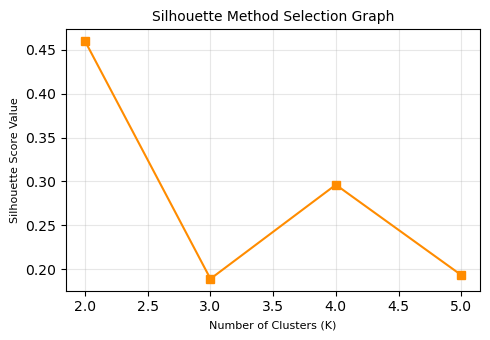

In [11]:
# plot size set small to save pages during printing
plt.figure(figsize=(5, 3.5))
plt.plot(cluster_range, sil_scores, marker='s', color='darkorange', linestyle='-')
plt.title('Silhouette Method Selection Graph', fontsize=10)
plt.xlabel('Number of Clusters (K)', fontsize=8)
plt.ylabel('Silhouette Score Value', fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout() # removes empty white borders
plt.show()

In [12]:
# identifying optimal partition cluster count from maximum peak score value
optimal_k = cluster_range[np.argmax(sil_scores)]
print(f"Optimal cluster count found from peak score: K = {optimal_k}")
final_model = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42)
df_subset = df.iloc[:1000].copy()
df_subset['Cluster_ID'] = final_model.fit_predict(X_sample)
print("\n=== Final Assigned Cluster Value Samples ===")
print(df_subset[['BALANCE', 'PURCHASES', 'CREDIT_LIMIT', 'Cluster_ID']].head(5))

Optimal cluster count found from peak score: K = 2

=== Final Assigned Cluster Value Samples ===
       BALANCE  PURCHASES  CREDIT_LIMIT  Cluster_ID
0    40.900749      95.40        1000.0           1
1  3202.467416       0.00        7000.0           1
2  2495.148862     773.17        7500.0           1
3  1666.670542    1499.00        7500.0           1
4   817.714335      16.00        1200.0           1
